# 01 · Data audit

**Goal:** describe the raw data *without changing it*: grain, structure, duplicates, missing values, ranges, target and leakage.
The output is a list of findings and hypotheses for the root cause. No cleaning or modelling here.

| # | Question |
|---|---|
| Q0 | First look: does the file match the statement? |
| Q1 | Grain: one row per batch? |
| Q2 | Structure: dates, plants, reactors, nesting |
| Q3 | Duplicates |
| Q4 | Missing values (where, not only how many) |
| Q5 | Ranges: sensor errors vs process anomalies |
| Q6 | Target distribution and trends |
| Q7 | Leakage: derived columns and variable timing |
| Q8 | First hypotheses |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src"))  # make `fragrance` importable without installing it

import pandas as pd
from fragrance import audit, config

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

**The plan in one picture.** Four notebooks, each building on the previous one: understand the data, fix only real sensor errors, find the causes, and only then build a model. This diagram opens the presentation.

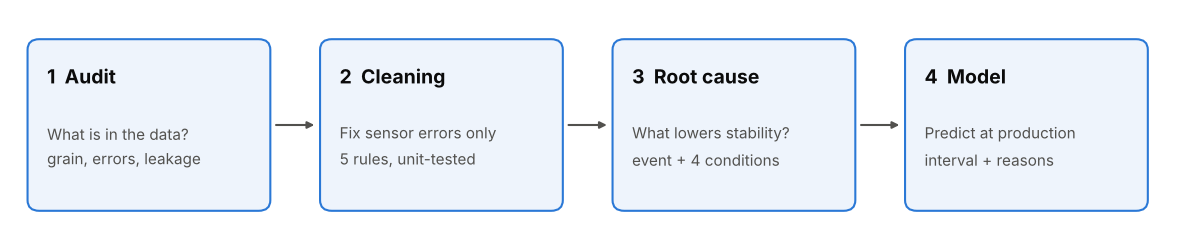

In [2]:
from fragrance import plots

plots.approach_diagram([("1  Audit", "What is in the data?\ngrain, errors, leakage"),
                        ("2  Cleaning", "Fix sensor errors only\n5 rules, unit-tested"),
                        ("3  Root cause", "What lowers stability?\nevent + 4 conditions"),
                        ("4  Model", "Predict at production\ninterval + reasons")],
                       filename="project_phases.png");

## Q0 · First look
Load the file untouched and compare its columns with what the statement (and `config.py`) describes.

In [3]:
df = audit.load_raw()
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")
df.head()

259,200 rows x 16 columns, 57 MB in memory


,batch_id,event_timestamp,plant_location,plant_country,production_line_id,temp_value,temp_unit,vessel_pressure_bar,refractive_index,density_g_cm3,ph_level,mixing_torque_nm,mass_flow_rate_kg_h,stability_months,purity_grade,oxidation_risk_flag
0,BATCH-2023-000001,2023-06-02 03:05:00,Plant-05,Country-05,Fragrance-Synthesis-Reactor-02,82.3319,C,2.46575,1.465316,0.858032,NaN,11.97486,492.9606,21.090538,Industrial Grade,False
1,BATCH-2023-000002,2023-04-12 02:47:30,Plant-05,Country-05,Fragrance-Synthesis-Reactor-04,91.7391,C,2.24107,1.455938,0.876435,5.79598,11.85726,449.9237,21.202418,Industrial Grade,False
2,BATCH-2023-000003,2023-06-03 11:35:30,Plant-03,Country-03,Fragrance-Synthesis-Reactor-07,85.0281,C,2.34404,1.468787,0.848555,5.31299,12.02680,437.1050,22.515180,Industrial Grade,False
3,BATCH-2023-000004,2023-05-11 02:43:00,Plant-04,Country-04,Fragrance-Synthesis-Reactor-05,88.5994,C,2.10548,1.447880,0.871153,5.44103,11.67030,439.3516,19.843445,Technical Grade,True
4,BATCH-2023-000005,2023-05-19 13:12:30,Plant-01,Country-01,Fragrance-Synthesis-Reactor-01,82.4168,C,2.16206,NaN,0.840569,5.06367,12.24158,447.2072,24.464046,Industrial Grade,False


In [4]:
audit.schema_vs_statement(df)

,column,in_file,in_config,dtype
0,batch_id,True,True,str
1,density_g_cm3,True,True,float64
2,event_timestamp,True,True,str
3,mass_flow_rate_kg_h,True,True,float64
4,mixing_torque_nm,True,True,float64
5,oxidation_risk_flag,True,True,bool
6,ph_level,True,True,float64
7,plant_country,True,True,str
8,plant_location,True,True,str
9,production_line_id,True,True,str


**Notes (to discuss):**
- Temperature comes as `temp_value` + `temp_unit`, not `reaction_temperature_celsius`. Are all readings in °C? (Q5)
- There is a `plant_location` column the statement does not mention. How does it relate to `plant_country`? (Q2)
- The statement says `BATCH-2026-XXXXXX`, but the IDs say 2023. Do the dates cover 90 days? (Q2)

## Q1 · Grain
Count the rows and the distinct values per `batch_id` with `audit.rows_per_batch`.

In [5]:
import importlib; importlib.reload(audit)   # picks up your edits without restarting the kernel

grain = audit.rows_per_batch(df)
print(grain["n_rows"].value_counts().sort_index())
grain.describe()

n_rows
1    259200
Name: count, dtype: int64


,n_rows,n_target,n_reactor,n_temp,n_pressure
count,259200.0,259200.0,259200.0,259200.000000,259200.000000
mean,1.0,1.0,1.0,0.910610,0.911362
std,0.0,0.0,0.0,0.285307,0.284221
min,1.0,1.0,1.0,0.000000,0.000000
25%,1.0,1.0,1.0,1.000000,1.000000
50%,1.0,1.0,1.0,1.000000,1.000000
75%,1.0,1.0,1.0,1.000000,1.000000
max,1.0,1.0,1.0,1.000000,1.000000


**Q1 · Grain: one row = one batch.**

*Evidence:* 259,200 rows and 259,200 unique `batch_id` (`n_rows = 1` for every batch).

*Implications:*
1. No aggregation needed: the table is already at the level of the target, which is measured once per batch.
2. A row-level split cannot leak a batch, but batches from the same reactor minutes apart are highly correlated, so we will also evaluate with a time-based split.
3. ~78 batches per physical reactor per day (median gap 14 min, see Q2) is unusually fast for batch reactors: to confirm with the process engineers what a "batch" represents.

## Q2 · Structure
Five questions: (2a) can every timestamp be read, and in which format? (2b) does the data cover 90 days? (2c) how do plants, countries and reactors relate? (2d) is production evenly spread over reactors and days? (2e) are the category labels clean?

### 2a · Timestamp formats
A single-format parse fails on ~25k rows. Before calling them broken, check whether they are the same date written differently.

In [6]:
importlib.reload(config); importlib.reload(audit)
audit.timestamp_formats(df["event_timestamp"])

,n,example,share,has_time
iso,234093,2023-06-02 03:05:00,0.903137,True
day_month_year,13024,16/06/2023,0.050247,False
month_name,12083,"May 15, 2023",0.046617,False


The slash format is **day/month/year**, not month/day: the first field goes above 12, the second never does (a check that rules out ambiguity, not an assumption).

In [7]:
first, second = df["event_timestamp"].str.extract(r"^(\d{2})/(\d{2})/").dropna().astype(int).T.values
print(f"first field > 12: {(first > 12).sum():,} | second field > 12: {(second > 12).sum():,}")

first field > 12: 7,815 | second field > 12: 0


### 2b · Date range

In [8]:
ts = audit.parse_timestamps(df["event_timestamp"])
print(f"unparsed: {ts.isna().sum()} | from {ts.min()} to {ts.max()} | {ts.dt.normalize().nunique()} distinct days")

unparsed: 0 | from 2023-04-01 00:00:00 to 2023-06-29 23:59:30 | 90 distinct days


### 2c · Plants, countries and reactors
Is `plant_location` just another name for `plant_country`? And does each reactor ID belong to one plant?

In [9]:
audit.category_mapping(df, "plant_location", "plant_country")

plant_country,Country-01,Country-02,Country-03,Country-04,Country-05
plant_location,,,,,
Plant-01,70644,0,0,0,0
Plant-02,0,35140,0,0,0
Plant-03,0,0,48823,0,0
Plant-04,0,0,0,55858,0
Plant-05,0,0,0,0,48735


In [10]:
audit.category_mapping(df, "production_line_id", "plant_location")

plant_location,Plant-01,Plant-02,Plant-03,Plant-04,Plant-05
production_line_id,,,,,
Fragrance-Synthesis-Reactor-01,5598,6180,5753,5771,5753
Fragrance-Synthesis-Reactor-02,6140,6341,6425,6088,6452
Fragrance-Synthesis-Reactor-03,6122,7296,6486,6404,6463
Fragrance-Synthesis-Reactor-04,7070,7459,7116,7029,7057
Fragrance-Synthesis-Reactor-05,6950,7864,7537,7172,7428
Fragrance-Synthesis-Reactor-06,7015,0,7813,7426,7770
Fragrance-Synthesis-Reactor-07,7658,0,7693,7738,7812
Fragrance-Synthesis-Reactor-08,7840,0,0,8230,0
Fragrance-Synthesis-Reactor-09,8104,0,0,0,0


In [11]:
df["reactor"] = audit.physical_reactor(df)   # audit-only helper column: plant + reactor ID
print(f"{df['reactor'].nunique()} physical reactors")
df.groupby("plant_location")["production_line_id"].nunique().rename("reactors per plant")

37 physical reactors


plant_location
Plant-01    10
Plant-02     5
Plant-03     7
Plant-04     8
Plant-05     7
Name: reactors per plant, dtype: int64

### 2d · Batches per reactor and day
White cells mean no batch that day. Only ISO timestamps are reliable to the minute, but all formats give the day.

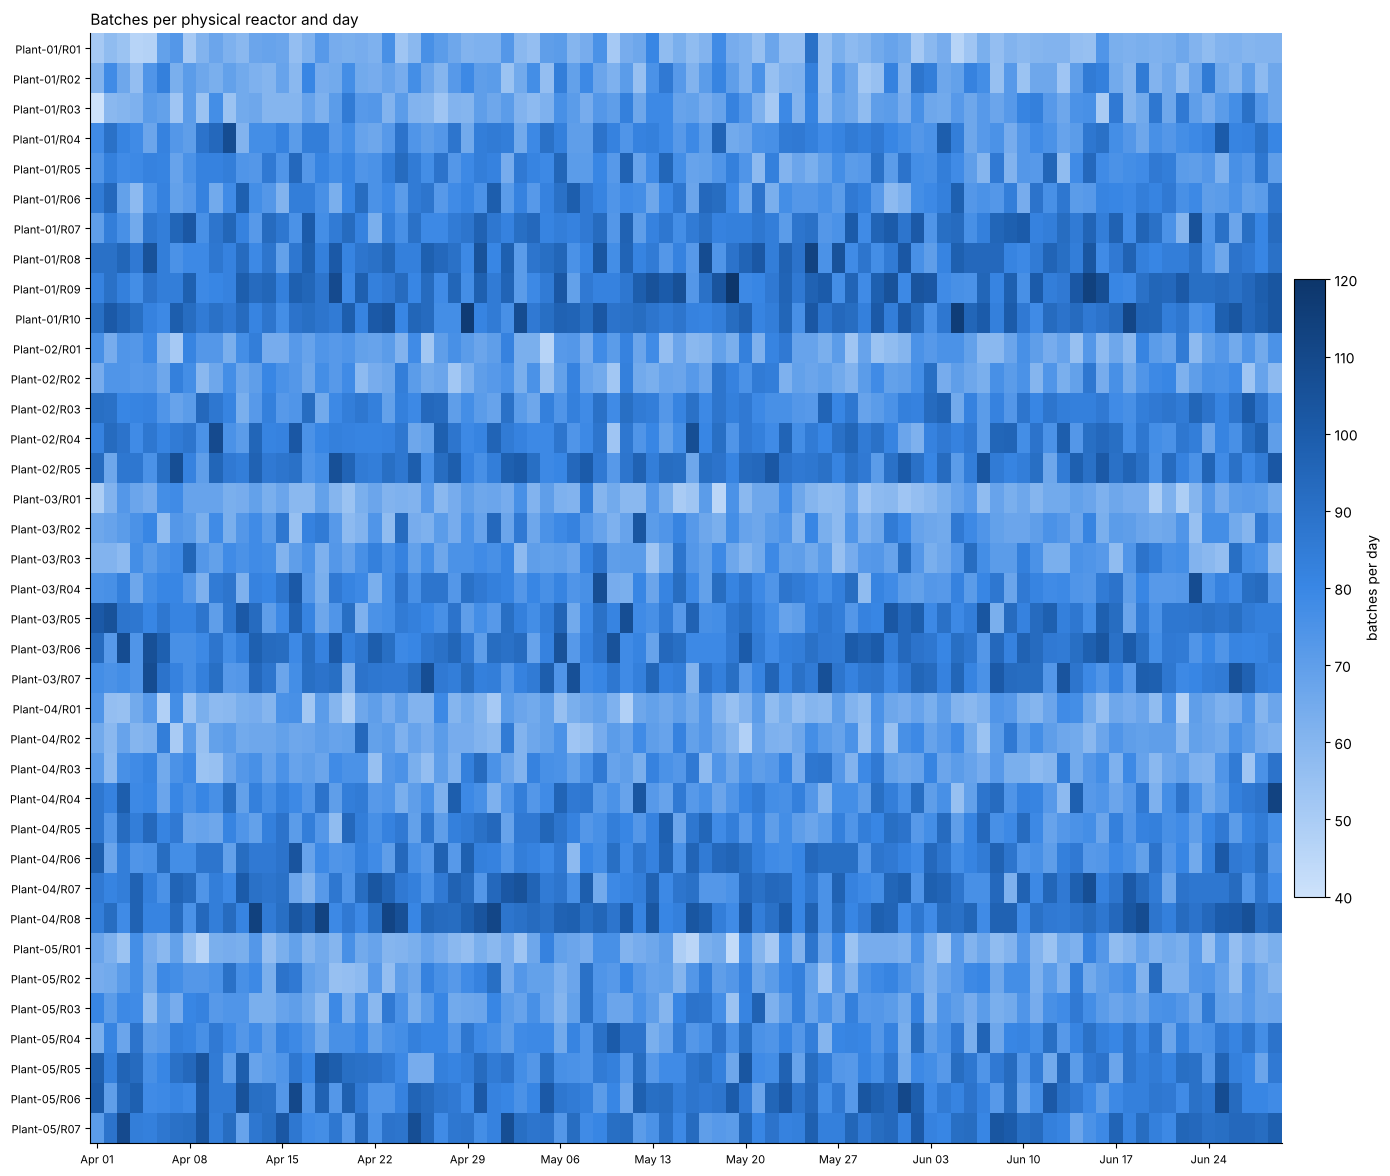

In [12]:
from fragrance import plots

per_day = audit.batches_per_day(df, ts, df["reactor"])
plots.count_heatmap(per_day, "Batches per physical reactor and day", "batches per day",
                    filename="audit_batches_per_reactor_day.png");

In [13]:
per_reactor = per_day.sum(axis=1)
iso_rows = df["event_timestamp"].str.match(r"^\d{4}-")   # only ISO rows carry a time of day
d = df.loc[iso_rows].assign(ts=ts[iso_rows]).sort_values(["reactor", "ts"])
gap_min = d.groupby("reactor")["ts"].diff().dt.total_seconds() / 60

print(f"batches per reactor: min {per_reactor.min():,}, median {per_reactor.median():,.0f}, max {per_reactor.max():,}")
print(f"batches per reactor per day: {len(df) / df['reactor'].nunique() / 90:.0f} on average")
print(f"gap between consecutive batches (ISO rows only): median {gap_min.median():.0f} min, "
      f"zero-minute gaps {(gap_min == 0).sum():,}")

batches per reactor: min 5,598, median 7,070, max 8,230
batches per reactor per day: 78 on average
gap between consecutive batches (ISO rows only): median 14 min, zero-minute gaps 2,810


### 2e · Category labels
Typos, case or spacing variants silently split one category into several. `hidden_variant` flags values that differ only by case or spaces.

In [14]:
audit.categorical_values(df, ["plant_location", "plant_country", "production_line_id", "temp_unit", "purity_grade", "oxidation_risk_flag"])

,column,value,n,hidden_variant
0,plant_location,Plant-01,70644,False
1,plant_location,Plant-04,55858,False
2,plant_location,Plant-03,48823,False
3,plant_location,Plant-05,48735,False
4,plant_location,Plant-02,35140,False
5,plant_country,Country-01,70644,False
6,plant_country,Country-04,55858,False
7,plant_country,Country-03,48823,False
8,plant_country,Country-05,48735,False
9,plant_country,Country-02,35140,False


**Q2 conclusions**
- **Timestamps:** three formats, all parseable: 90.3% ISO with time, 9.7% date-only (`dd/mm/yyyy` or `Mon dd, yyyy`). No date is lost, but those rows lose the time of day. → Phase 2: parse all three; time-of-day analyses use ISO rows only.
- **Range:** 2023-04-01 to 2023-06-29, exactly 90 days (the statement says 2026: only a labelling difference).
- **`plant_location` ↔ `plant_country` is one-to-one** → redundant; keep one.
- **Reactor IDs are reused across plants:** "Reactor-05" exists in all five plants. There are **37 physical reactors**, not 10 (Plant-01: 10, Plant-02: 5, Plant-03: 7, Plant-04: 8, Plant-05: 7). Reactors 09–10 only exist in Plant-01, which explains their low totals. → Every reactor-level analysis must use plant + reactor. Question for the stakeholders: does "10 synthesis reactors" mean 10 reactor *designs*?
- **Load:** ~78 batches per physical reactor per day, median 14 min between batches. No downtime: every reactor produced every day. Within each plant, load rises with the reactor number (R01 lightest). Whether higher load relates to stability is a phase 3 question.
- **Labels (2e):** no typos, case or spacing variants. `temp_unit` has two units (°C and °F, Q5) and is missing exactly where `temp_value` is missing.
- **Open:** some consecutive batches on the same reactor share the exact same timestamp → check in Q3 (duplicates).

## Q3 · Duplicates
Three kinds: identical rows, rows identical except for `batch_id` (the same record re-ingested under a new ID, which a plain `duplicated()` misses), and repeated IDs.

In [15]:
audit.duplicate_report(df)

identical rows               0
identical except batch_id    0
repeated batch_id            0
dtype: int64

The 2,810 zero-minute gaps from Q2 are therefore **different batches** (different sensor values and targets) logged at the same 30-second timestamp on the same reactor, not copies. Timestamps have 30 s resolution, so two batches can share one.

**Q3 conclusion:** no duplicates of any kind. Nothing to remove.

## Q4 · Missing values
Not only *how many*, but *where* (plant, reactor, day), *how* (one sensor or all at once) and *whether it relates to the target*. In Rubin's terms: MCAR (completely at random) can be imputed or dropped without bias; MAR/MNAR cannot.

In [16]:
sensors = config.SENSOR_COLS
audit.missing_report(df, sensors).T.round(4)

,temp_value,vessel_pressure_bar,refractive_index,density_g_cm3,ph_level,mixing_torque_nm,mass_flow_rate_kg_h
share_missing,0.0894,0.0886,0.0886,0.0889,0.0885,0.0883,0.0894


In [17]:
print("Sensors missing per row:")
audit.missing_per_row(df, sensors).to_frame().assign(share=lambda t: (t["rows"] / len(df)).round(4))

Sensors missing per row:


,rows,share
0,153331,0.5916
1,79960,0.3085
2,18116,0.0699
3,2268,0.0088
4,171,0.0007
5,10,0.0000
7,5344,0.0206


Two mechanisms are visible:
- **Single-sensor dropouts:** each sensor loses ~6.9% of its readings independently (1 to 5 missing per row).
- **Whole-record loss:** 5,344 rows (2.1%) have *all seven* sensors missing and no row has exactly 6. If sensors failed independently, all-seven would be ~5 in a million rows, not 2 in a hundred. This is a separate failure, e.g. the data logger dropping the record.

In [18]:
print("Share missing by plant:")
display(audit.missing_report(df, sensors, by=df["plant_location"]).round(3))
by_reactor = audit.missing_report(df, sensors, by=df["reactor"]).mean(axis=1)
by_day = audit.missing_report(df, sensors, by=ts.dt.normalize()).mean(axis=1)
print(f"mean share missing per reactor: {by_reactor.min():.3f} to {by_reactor.max():.3f}")
print(f"mean share missing per day:     {by_day.min():.3f} to {by_day.max():.3f}")

Share missing by plant:


,temp_value,vessel_pressure_bar,refractive_index,density_g_cm3,ph_level,mixing_torque_nm,mass_flow_rate_kg_h
plant_location,,,,,,,
Plant-01,0.091,0.090,0.090,0.090,0.087,0.089,0.089
Plant-02,0.091,0.086,0.089,0.089,0.088,0.088,0.091
Plant-03,0.088,0.089,0.088,0.087,0.088,0.088,0.089
Plant-04,0.089,0.089,0.089,0.088,0.090,0.088,0.089
Plant-05,0.088,0.088,0.087,0.090,0.091,0.087,0.090


mean share missing per reactor: 0.085 to 0.093
mean share missing per day:     0.082 to 0.094


The same table as a picture: every cell is close to 9%, with no plant or sensor standing out. A flat map is what missing completely at random looks like.

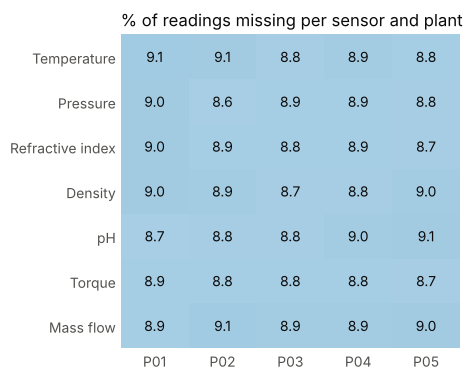

In [19]:
share = audit.missing_report(df, sensors, by=df["plant_location"]).T * 100
share.index = ["Temperature", "Pressure", "Refractive index", "Density", "pH", "Torque", "Mass flow"]
share.columns = [c.replace("Plant-", "P") for c in share.columns]
plots.share_heatmap(share, "% of readings missing per sensor and plant", filename="audit_missing_by_plant.png");

In [20]:
y = df[config.TARGET]
pd.DataFrame({c: y.groupby(df[c].isna()).mean() for c in sensors}).rename(index={False: "present", True: "missing"}).round(3)

,temp_value,vessel_pressure_bar,refractive_index,density_g_cm3,ph_level,mixing_torque_nm,mass_flow_rate_kg_h
present,21.533,21.533,21.533,21.530,21.534,21.533,21.534
missing,21.517,21.521,21.519,21.553,21.510,21.518,21.507


**Q4 conclusions**
- Each sensor is missing ~8.9% of the time (~23k rows each); 40.8% of rows miss at least one sensor, so dropping incomplete rows would throw away 4 batches in 10.
- Missingness is **flat** across plants (8.6–9.1%), reactors (8.5–9.3%) and days (8.2–9.4%), and the target mean is the same whether a value is present or missing (21.5 either way). → Consistent with **MCAR**: sensor errors, not process signal.
- Two mechanisms: independent single-sensor dropouts plus 5,344 whole-record losses (2.1%), which have no sensor information at all.
- → Phase 2: keep rows with a few missing values (LightGBM handles NaN natively; impute for linear baselines); decide what to do with the 5,344 empty records (they cannot be predicted from sensors).

## Q5 · Ranges: sensor errors vs process anomalies
Every sensor reading gets one label: **missing**, **sentinel** (a fixed code repeated hundreds of times), **impossible** (negative where physics forbids it), **below** / **normal** / **above** the normal range of the statement. Temperature is judged in °C after converting the °F readings.

Rule of thumb: a **sensor error** is physically impossible, a fixed code, or unrelated to the target; a **process anomaly** is plausible and moves the target.

### 5a · Temperature units
The file has a `temp_unit` column. What do °F readings look like?

In [21]:
df.groupby("temp_unit")["temp_value"].describe().round(2)

,count,mean,std,min,25%,50%,75%,max
temp_unit,,,,,,,,
C,234524.0,86.22,6.84,78.96,82.78,85.96,89.16,210.0
F,1506.0,189.05,25.86,174.68,180.53,186.39,192.24,410.0


In [22]:
t_c = audit.temperature_celsius(df)
print("°F readings converted to °C:")
t_c[df["temp_unit"].eq("F") & ~df["temp_value"].isin(config.SENTINELS["temp_value"])].describe().round(2)

°F readings converted to °C:


count    1487.00
mean       85.68
std         3.73
min        79.27
25%        82.50
50%        85.72
75%        88.85
max        92.09
Name: temp_value, dtype: float64

1,487 readings are genuine °F (175–192 °F = 79–89 °C, a normal process temperature). Left unconverted, they would be read as 190 °C and flagged as the most extreme anomalies in the dataset. 210 is a sentinel in °C, and 410 is the same code written in °F (210 °C = 410 °F).

### 5b · Status of every reading

In [23]:
audit.range_report(df)

,missing,sentinel,impossible,below,normal,above
temp_value,23170,526,0,0,235504,0
vessel_pressure_bar,22975,544,0,509,235172,0
refractive_index,22971,0,0,0,236229,0
density_g_cm3,23043,558,0,0,235599,0
ph_level,22937,543,0,3396,228082,4242
mixing_torque_nm,22880,0,0,0,232467,3853
mass_flow_rate_kg_h,23162,0,0,0,235582,456


In [24]:
print("Most frequent values per sensor (a sentinel is one value repeated hundreds of times):")
pd.DataFrame({c: df[c].value_counts().head(2).index.tolist() + df[c].value_counts().head(2).tolist() for c in sensors},
             index=["value 1", "value 2", "count 1", "count 2"]).T

Most frequent values per sensor (a sentinel is one value repeated hundreds of times):


,value 1,value 2,count 1,count 2
temp_value,210.000000,410.000000,507.0,19.0
vessel_pressure_bar,-1.000000,2.059790,544.0,19.0
refractive_index,1.458878,1.459178,49.0,49.0
density_g_cm3,860.000000,0.864106,558.0,51.0
ph_level,14.000000,5.793650,543.0,14.0
mixing_torque_nm,12.250460,12.408700,16.0,15.0
mass_flow_rate_kg_h,514.504600,477.972200,5.0,5.0


In [25]:
bad = pd.concat([audit.sensor_status(df, c).eq("sentinel") for c in sensors], axis=1).any(axis=1)
print("Rows with a sentinel by plant:", df.loc[bad, "plant_location"].value_counts().to_dict())
print("Rows in °F by plant:          ", df.loc[df["temp_unit"].eq("F"), "plant_location"].value_counts().to_dict())
p4 = df["plant_location"].eq("Plant-04")
print(f"Plant-04 mean stability: rows with sentinel {y[p4 & bad].mean():.2f} vs rows without {y[p4 & ~bad].mean():.2f}")

Rows with a sentinel by plant: {'Plant-04': 2136}
Rows in °F by plant:           {'Plant-04': 1506}
Plant-04 mean stability: rows with sentinel 21.00 vs rows without 21.06


The values beyond the normal range that are *not* sentinels are close to the edges:
- pressure 1.989–2.000 bar (just under 2);
- torque up to 12.56 N·m (just over 12.5);
- flow up to 522 kg/h (just over 520);
- pH 4.95–4.99 and 6.0–6.1.

None is physically impossible. Pressure −1 bar is labelled *sentinel* (one fixed value, 544 times) rather than *impossible*; there are no other negatives.

### 5c · Error or signal? Mean stability by status

In [26]:
status_effect = pd.concat({c: audit.target_by_status(df, c) for c in sensors}, names=["sensor", "status"]).round(2)
status_effect

n  mean_stability
sensor              status                          
temp_value          missing    23170           21.52
                    sentinel     526           21.02
                    normal    235504           21.53
vessel_pressure_bar missing    22975           21.52
                    sentinel     544           21.00
                    below        509           20.53
                    normal    235172           21.54
refractive_index    missing    22971           21.52
                    normal    236229           21.53
density_g_cm3       missing    23043           21.55
                    sentinel     558           20.99
                    normal    235599           21.53
ph_level            missing    22937           21.51
                    sentinel     543           21.01
                    below       3396           20.39
                    normal    228082           21.59
                    above       4242           19.60
mixing_torque_nm    missing    22880           21.52
                    normal    232467           21.48
                    above       3853           24.46
mass_flow_rate_kg_h missing    23162           21.51
                    normal    235582           21.53
                    above        456           21.75

**Error vs signal in one picture.** Left: inside Plant-04, rows with a sentinel code have the same stability as the rest, so the code carries no information about the batch: it is an error. Right: pH outside its normal range comes with clearly lower stability, so it is a real process value and must be kept.

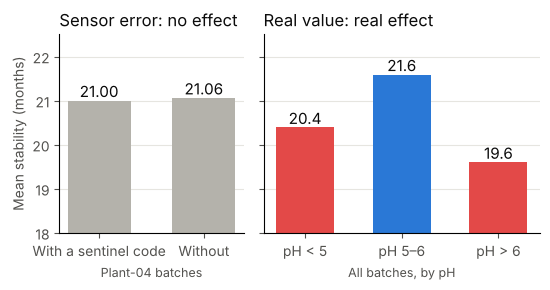

In [27]:
error = pd.Series({"With a sentinel code": y[p4 & bad].mean(), "Without": y[p4 & ~bad].mean()})
ph = status_effect.loc["ph_level", "mean_stability"]
signal = pd.Series({"pH < 5": ph["below"], "pH 5–6": ph["normal"], "pH > 6": ph["above"]})
plots.error_vs_signal(error, signal, "Plant-04 batches", "All batches, by pH", filename="audit_errors_vs_signal.png");

### 5d · Frozen readings and spikes
Per physical reactor, in time order. A frozen sensor repeats the exact same value on consecutive batches; a spike is one reading far from its neighbours (robust z-score on a rolling median ± MAD, |z| > 5).

In [28]:
pd.DataFrame({c: pd.concat([audit.stuck_runs(df, c, ts, df["reactor"]),
                             pd.Series({"spikes_z>5": audit.spike_count(df, c, ts, df["reactor"])})])
              for c in sensors}).T

,runs,rows_in_runs,longest_run,spikes_z>5
temp_value,0,0,2,24
vessel_pressure_bar,0,0,2,15
refractive_index,0,0,2,22
density_g_cm3,2,6,3,22
ph_level,0,0,2,19
mixing_torque_nm,0,0,2,16
mass_flow_rate_kg_h,0,0,1,22


**Q5 conclusions**

*Sensor errors* (to clean in phase 2):
- **Sentinels:** 210 °C / 410 °F (526), −1 bar (544), 860 g/cm³ (558), pH 14 (543). Every one of them is in **Plant-04**, as are all 1,506 °F readings. This points to a data-acquisition problem in one plant (logger configuration), not to the process.
- Within Plant-04, rows with a sentinel have the same stability as rows without one (21.0 vs 21.1). A sentinel does not move the target, which confirms it is an error. (Across all plants sentinel rows look lower, 21.0 vs 21.5, only because they all come from Plant-04, which is lower overall: a confounder.)
- **Units:** 1,487 genuine °F readings → convert, do not delete.
- **Frozen readings:** none (longest run of identical values: 2–3 batches). **Spikes:** 15–24 per sensor (< 0.01%), negligible.

*Candidate process anomalies* (the signal for phase 3):
- **pH outside 5–6:** 3,396 below and 4,242 above. Mean stability 20.4 and 19.6 months, versus 21.6 when pH is normal.
- **Pressure just under 2 bar:** 509 rows, almost all in Plant-02. Mean stability 20.5 vs 21.4 for the rest of Plant-02.
- **Torque above 12.5:** 3,853 rows, with *higher* stability (24.5). Torque seems to matter in both directions (Q8).
- **The normal ranges of the statement are not enough on their own:** torque between 10 and 11.4 N·m is "normal" by the statement (9–12.5), yet every one of the 11,635 readings below 11.44 N·m comes from one abnormal regime (Q8).

## Q6 · Target: `stability_months`
Distribution, then where and when it is low: by plant, by physical reactor, by week.

count    259200.00
mean         21.53
std           2.05
min          18.02
25%          19.91
50%          21.23
75%          22.91
max          28.61
Name: stability_months, dtype: float64


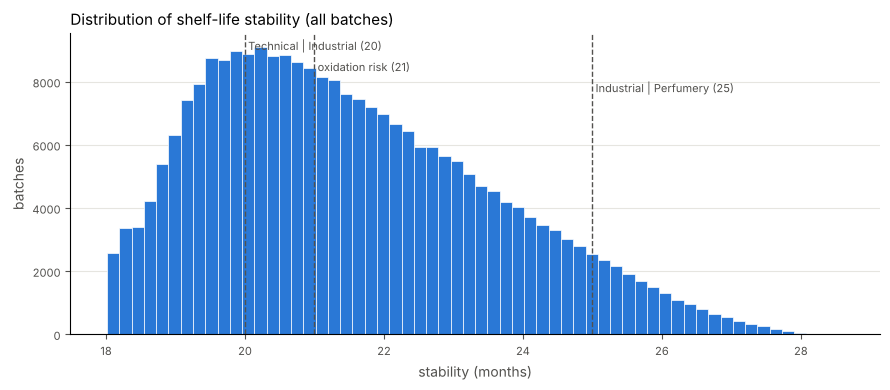

In [29]:
print(y.describe().round(2))
plots.histogram_with_thresholds(y, {"Technical | Industrial (20)": 20, "oxidation risk (21)": 21, "Industrial | Perfumery (25)": 25},
                                "Distribution of shelf-life stability (all batches)", "stability (months)",
                                filename="audit_target_distribution.png");

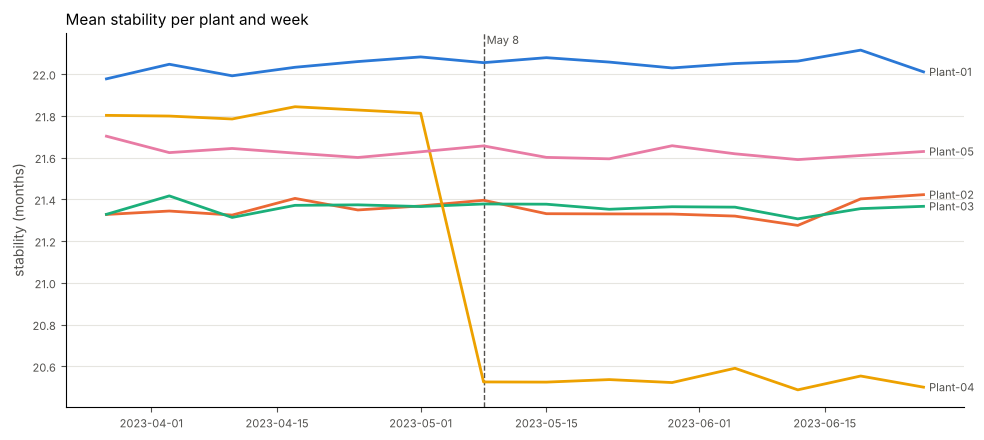

In [30]:
weekly = y.groupby([ts.dt.to_period("W").dt.start_time, df["plant_location"]]).mean().unstack()
plots.lines_by_group(weekly, "Mean stability per plant and week", "stability (months)",
                     event=(pd.Timestamp("2023-05-08"), "May 8"), filename="audit_stability_week_plant.png");

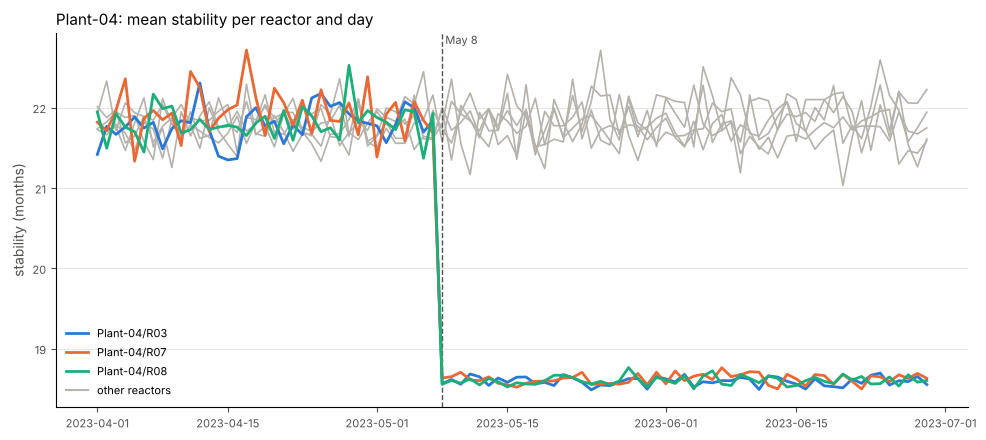

In [31]:
p4 = df["plant_location"].eq("Plant-04")
daily_p4 = y[p4].groupby([ts[p4].dt.normalize(), df.loc[p4, "reactor"]]).mean().unstack()
plots.lines_by_group(daily_p4, "Plant-04: mean stability per reactor and day", "stability (months)",
                     highlight=["Plant-04/R03", "Plant-04/R07", "Plant-04/R08"],
                     event=(pd.Timestamp("2023-05-08"), "May 8"), filename="audit_plant04_reactors_daily.png");

In [32]:
before = ts < "2023-05-08"
shift = y.groupby([df["reactor"], before]).mean().unstack().rename(columns={True: "before May 8", False: "from May 8"})
shift = shift[["before May 8", "from May 8"]]
shift["change"] = shift["from May 8"] - shift["before May 8"]
print(f"largest change among the other {len(shift) - 3} reactors: {shift['change'].drop(['Plant-04/R03', 'Plant-04/R07', 'Plant-04/R08']).abs().max():.2f} months")
shift.sort_values("change").head(6).round(2)

largest change among the other 34 reactors: 0.13 months


,before May 8,from May 8,change
reactor,,,
Plant-04/R07,21.92,18.62,-3.30
Plant-04/R08,21.82,18.60,-3.21
Plant-04/R03,21.79,18.59,-3.20
Plant-02/R01,21.47,21.39,-0.08
Plant-05/R02,21.76,21.70,-0.06
Plant-05/R01,21.70,21.65,-0.06


**Q6 conclusions**
- Stability ranges 18.0–28.6 months, mean 21.5, right-skewed. Most batches sit in the lower half of the 18–30 specification: 27% are Technical grade (< 20 months), only 7% Perfumery (≥ 25).
- Week by week, the plants run at similar levels except Plant-04 from May 8 (plant differences are measured in phase 3, 03 §3.4).
- **The one sharp event:** from **2023-05-08**, Plant-04 drops from ~21.8 to ~20.5 months and stays there. The drop comes entirely from **three reactors, R03, R07 and R08**, which lose ~3.2 months (21.8 → 18.6) overnight. No other reactor, in any plant, moves by more than 0.13 months.
- A step change on a specific date, in specific equipment, is the signature of an **event** (maintenance, a raw-material lot, a setting change), not of slow wear.

## Q7 · Leakage
**(a) Derived columns.** If each value of a derived column covers a target range that does not overlap with the others, the column is just a threshold on the target.

In [33]:
audit.leakage_thresholds(df).round(3)

,column,value,min,max,size
0,purity_grade,Technical Grade,18.015,20.000,69248
1,purity_grade,Industrial Grade,20.000,25.000,172452
2,purity_grade,Perfumery Grade,25.000,28.609,17500
3,oxidation_risk_flag,True,18.015,21.000,119017
4,oxidation_risk_flag,False,21.000,28.609,140183


**(b) When is each variable available?** The model should predict at production time, so a feature is only legitimate if it is known by then.

| Variable | Available | Use as feature? |
|---|---|---|
| plant, reactor, timestamp | before / at start of batch | yes |
| temperature, pressure, pH, torque, mass flow, refractive index | during the reaction | yes |
| density | after the separation step (end of batch) | yes for an end-of-batch prediction; no if predicting before separation → test both variants in phase 4 |
| `purity_grade`, `oxidation_risk_flag` | after the lab stability test (months later) | **never** |

**Q7 conclusions**
- `purity_grade` is a pure threshold on stability: Technical < 20 ≤ Industrial < 25 ≤ Perfumery, with no overlap.
- `oxidation_risk_flag` = stability < 21 months, also with no overlap.
- Both are excluded from the features. Used as inputs, they would give near-perfect accuracy for a useless model, because they are only known after the stability test.
- They remain useful as **business language**: "Technical grade" = < 20 months is how the Quality team will read our predictions.

## Q8 · First hypotheses
These are associations seen in the audit, to be **tested** in phase 3, not conclusions. A first look at which sensors move together with stability (Spearman rank correlation, sensor errors excluded); the shape of each effect is studied in phase 3.

In [34]:
from scipy.stats import spearmanr

clean = {c: (t_c if c == "temp_value" else df[c]).where(audit.sensor_status(df, c).isin(["below", "normal", "above"])) for c in sensors}
rho = pd.Series({c: spearmanr(v[v.notna()], y[v.notna()]).statistic for c, v in clean.items()}).round(3)
rho.sort_values(key=abs, ascending=False).rename("Spearman rho with stability (sensor errors excluded)")

mixing_torque_nm       0.726
temp_value            -0.372
refractive_index       0.125
density_g_cm3         -0.042
ph_level              -0.031
vessel_pressure_bar   -0.009
mass_flow_rate_kg_h   -0.000
Name: Spearman rho with stability (sensor errors excluded), dtype: float64

In [35]:
affected = df["reactor"].isin(["Plant-04/R03", "Plant-04/R07", "Plant-04/R08"]) & (ts >= "2023-05-08")
print(f"affected regime: {affected.sum():,} batches ({affected.mean():.1%}), mean stability {y[affected].mean():.2f} vs {y[~affected].mean():.2f}")
print(f"share of all batches below 19 months that come from it: {(affected & (y < 19)).sum() / (y < 19).sum():.0%}")

affected regime: 13,145 batches (5.1%), mean stability 18.61 vs 21.69
share of all batches below 19 months that come from it: 48%


**Q8 hypotheses (to test in phase 3)**

| # | Hypothesis | Evidence so far | How to test / confirm |
|---|---|---|---|
| **H1** | **An event on 2023-05-08 in Plant-04 reactors R03, R07, R08 cut stability by ~3.2 months.** | Q6: 13,145 batches (5.1%) at 18.6 months; they make up 48% of all batches below 19 months. No other reactor changes. | What changed in the process (control charts, comparison with the other Plant-04 reactors, sensor shifts). **Confirm with the plant:** maintenance logs, agitator or motor changes, raw-material lots used by those three reactors from May 8. |
| **H2** | **Mixing torque is the main process driver of stability**, even inside the normal range: more torque means more stability (Spearman ρ = 0.73). | Strongest correlation of all sensors. | Partial dependence and SHAP, checking that it holds outside the H1 regime. Ask the engineers what a lower torque means physically (viscosity, agitator speed). |
| **H3** | **Higher reaction temperature lowers stability** (ρ = −0.37). Consistent with thermal degradation or oxidation of fragrance molecules. | Second-strongest correlation. | Same as H2, plus the temperature × torque interaction. A small designed experiment (DoE) at two temperatures would confirm causality. |
| **H4** | **pH outside 5–6 lowers stability, in both directions**, independently of H1. | Q5c: 20.4 months below pH 5 and 19.6 above pH 6, vs 21.6 inside 5–6. | Effect sizes with confidence intervals; check pH × temperature. |
| **H5** | **Pressure just below 2 bar in Plant-02** goes with lower stability (20.5 vs 21.4). | 509 rows, almost all in Plant-02. | Small effect; check whether it survives once torque and temperature are accounted for. |
| **D1** | **Plant-04 has a data-acquisition problem**, separate from the process: all sentinels and all °F readings. | Sentinel rows have the same stability as other Plant-04 rows. | Not a root cause of low stability, but a recommendation for the business: fix the logger configuration. |

**What the audit hands to phase 2 (cleaning):** convert °F → °C; set sentinels to missing; keep the slightly out-of-range values (they are signal); decide about the 5,344 empty records; parse the three timestamp formats; use plant + reactor as the reactor key; drop `plant_country` (redundant) and exclude the two leakage columns.